# STATE OPUS-R1 — Intrinsic perturbation strength

All analysis code is inline. Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, statsmodels 0.14.2, matplotlib 3.9.4, RDKit 2026.3.3, IPython and ipykernel. Model evaluation uses released scores; no inference is required. `STATE_PUBLIC_INPUTS` and `STATE_RELEASE_INPUTS` can select verified raw caches.

## 1. Data source and acquisition

Download the pinned official STATE per-condition score files. The checksum-pinned companion bundle supplies condition identities, drug annotations and dated ontology membership snapshots.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,zipfile,shutil,ast,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,pearsonr,rankdata,mannwhitneyu
import statsmodels.api as sm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
START=time.time()
CACHE=Path(os.environ.get('STATE_PUBLIC_INPUTS','state_public_inputs')).resolve();CACHE.mkdir(parents=True,exist_ok=True)
RELEASES=Path(os.environ.get('STATE_RELEASE_INPUTS','state_releases')).resolve();RELEASES.mkdir(parents=True,exist_ok=True)
WORK=Path('test-04_outputs').resolve();(WORK/'data').mkdir(parents=True,exist_ok=True);(WORK/'spectra_run/artifacts').mkdir(parents=True,exist_ok=True)
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def fetch(url,p,size,digest):
    if p.exists() and p.stat().st_size==size and sha(p)==digest:return p
    p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix(p.suffix+'.part')
    with urllib.request.urlopen(urllib.request.Request(url,headers={'User-Agent':'STATE-notebook/1.0'}),timeout=180) as source,tmp.open('wb') as target:
        shutil.copyfileobj(source,target,8388608)
    if tmp.stat().st_size!=size or sha(tmp)!=digest:raise ValueError('Source identity mismatch: '+str(p))
    tmp.replace(p);return p
archive=fetch('https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/state-inputs.zip',CACHE/'state-inputs.zip',440390168,'fb45e9305dcf32bfa9d68ff910f7539707b3e4ff58c695db2e8c5ee8a9e8a9fc')
P=CACHE/'public_bundle/assets/state-opus-r1'
with zipfile.ZipFile(archive) as z:
    inventory=json.loads(z.read('STATE_INPUTS.json'))
    required=[k for k in inventory if k.startswith('state-opus-r1/') and (k.endswith('data/predictions.csv') or ('spectra_run/artifacts/' in k and k.endswith('.json')))]
    for k in required:
        target=CACHE/'public_bundle/assets'/k;x=inventory[k]
        if target.exists() and target.stat().st_size==x['bytes'] and sha(target)==x['sha256']:continue
        target.parent.mkdir(parents=True,exist_ok=True)
        with z.open('assets/'+k) as source,target.open('wb') as dest:shutil.copyfileobj(source,dest)
        if sha(target)!=x['sha256']:raise ValueError(k)
print('Verified input annotation files:',len(required))

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


Verified input annotation files: 1


In [2]:
SOURCES = [{'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 276570,
  'sha256': 'ca5377b00f6700bee2b4b17eeaf4e703fc2d3797ac8271c2f282088fcbb289e8',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269473,
  'sha256': '489cbe64636b7765fe7f24fe5536da9fb1ee86226effd9eeb422634d5731396b',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 284828,
  'sha256': '49e3ce723ec7ca6bfc044d438902129ffb9ec2682d33a73e16693735c4746ad4',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 275993,
  'sha256': 'f391f46e60061332b2a555567443aeb3190239c4bdac146bcb3340d503aeebe9',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/fewshot/state_generalization_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 272057,
  'sha256': '2654fe5b526d577807a63b30a9c85a70d829979afe452325650071a3f22a03ae',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-HVG-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332',
  'revision': 'ca6b751972493f8448e3256d1340ae70ad43e1e7'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 281263,
  'sha256': '9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269030,
  'sha256': '646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 287583,
  'sha256': '9106d01893815fbf77d85f4e2351da8a607adedc74edb62cc452c110812b09a2',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 277100,
  'sha256': '80c38255fdce0444457f909d7ef9c2186a82c5476550bfe82604bd48896aae72',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 273025,
  'sha256': '5a40d67c26a428487d3b0f602b5b7a69006b5c4595eaaf0ffb5f44eaf5160239',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
         '766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-SE-Tahoe',
  'filename': 'zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'path': 'scores/ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03',
  'revision': '03b1971d7cc93a7535fd2e957c6948dba267378b'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 360951,
  'sha256': '42dd8ef412843c9e0782c72d669ef352d40af63fbe7f1d11ab26b9d0f188a5e3',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 423657,
  'sha256': 'fff2d8598e61229052483d2215809b267a9be5b28187147ea8eaa078a115280d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 368088,
  'sha256': 'c518efe5a6492b62dd3aea985e6f50ca5a8b2e9df742134041e313d2e6605ba6',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 406063,
  'sha256': '397533d40a2efba9d75a54fca855fc39db1562ff50c765408e9afdea61826803',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 354986,
  'sha256': '1e4cd7df90212c61f7f171fcd5da69449e5e3edde4462201b8dedd99d07aa2c4',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 403167,
  'sha256': '7352c785869bf83402fb5dc79ebdbb2d911d77153c3530db4b9f143a5bec2626',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 365675,
  'sha256': 'bcba9ae671c391e78b11efda0bb0d3d48f8052541ae7599d522b293e96e3594c',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 411935,
  'sha256': '36b6afce7889485a2afa99a13449b59dbd06d14d564e985a37629f93101ffd34',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'path': 'scores/ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23267,
  'sha256': '09553a37706d948fddf8cf5bacf5b88880cf3cfb90a2b866f08524b49e909401',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22921,
  'sha256': 'e9d288b06289e24e7928b9a79ccce8ed74a702c9b2fdf92c5a6470aeb11cdbc1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20723,
  'sha256': '202ca8338564bcdc2a7c68007b0976800b4dbb7ca5e6d8a0799b0d428615233c',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 21260,
  'sha256': '13935da60494fb572039e10aed4f44748bf9e7e8dd0ee2acf4fe8bcfe158a852',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21542,
  'sha256': '1030abc5a7bd1cb1b9c692c35ba4ce16d0515d299dec9c7cf50eb2ede9641a65',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33745,
  'sha256': 'f6a553831669d4f5fb0a6957d7f32e815a4fa5be89a0cf13677396b6039aa157',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 32762,
  'sha256': '9a7f4a4c564d25dc2cfe06e25367ae936dc50873aa5711ad26e5d1e3f46d0916',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 27434,
  'sha256': '50b1d9d6f15cbd9d27ccb17e07605f21b94a0e461d346555d81b7d911694d5ec',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31420,
  'sha256': '84f0f00cd17c871b879ee38d92ce5183241c38e1afb20405f3b00e361c98eaa1',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-HVG-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-HVG-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Parse/resolve/827df657cd87063026d2abefd73e99036755ac1b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 31512,
  'sha256': 'df68464d3caf07c7c5129a0d911d10ba17c75020e7ac866e4afde28155ac4786',
  'revision': '827df657cd87063026d2abefd73e99036755ac1b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 23028,
  'sha256': '06ef8b31481e21845e29eb3408827469eb7da67c01e17c315d2e82d77ddd325a',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 22494,
  'sha256': '0073fb52db8657ccb14815b58025f53f89abde3a27eb1614c650e930375d3f60',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 20130,
  'sha256': '87c04e97d215f7bda9a13d602472e62db0be919dc791ab4c4d4732f5a48cf06c',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/fewshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 21275,
  'sha256': '3d8466310099d70f91a69725fb0e181e1fd541f57ed644daab5c41be6ae1b88d',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_0/eval_best.ckpt/B_Intermediate_Memory_results.csv',
  'bytes': 33911,
  'sha256': '41377aad49e688a710264d343378e5bc6ce1a698880b8bb1c4f0be9ad025c48f',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_1/eval_best.ckpt/B_Naive_results.csv',
  'bytes': 33789,
  'sha256': 'bb35f1b85f8d9603b10fcf8706602b122bdc520548c9c53f891386dcd40026a1',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_2/eval_best.ckpt/Plasmablast_results.csv',
  'bytes': 28814,
  'sha256': '73b37fc58ca8a8734dc5cc34c6b44ec94cdbb6ccb47dadfb3c5bccedf8c99655',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_3/eval_best.ckpt/CD4_Memory_results.csv',
  'bytes': 31883,
  'sha256': '2cbac97ecdeee9ae7333245fc4d06860969d17d38f2fc4ebea8f99e8af5657fa',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'},
 {'repo': 'arcinstitute/ST-SE-Parse',
  'filename': 'zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'path': 'scores/ST-SE-Parse/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Parse/resolve/fa458ffda8690c5c5bdff080dfdc46b46713043b/zeroshot/split_4/eval_best.ckpt/CD14_Mono_results.csv',
  'bytes': 30873,
  'sha256': '579286dcc83ffaead762b234891442b560b6213d847956d87147389323c7df5b',
  'revision': 'fa458ffda8690c5c5bdff080dfdc46b46713043b'}]

## 2. Data processing

Join released results to exact repository/path/perturbation identities. Keep the protocol, representation, context and annotation fields explicit. Each condition is retained once.

In [3]:
# Read only source identities and annotations from the bundle; model-score columns
# are loaded separately from the pinned official CSVs below.
annotation_columns=['source_repo','source_path','dataset_family','protocol','context','split_id','representation','perturbation','perturbation_name','dose','dose_unit','perturbation_norm','perturbation_loose','row_key','drug_metadata_match']
annotation_columns += [c for c in pd.read_csv(P/'data/predictions.csv',nrows=0).columns if c.startswith('drugmeta_')]
annotations=pd.read_csv(P/'data/predictions.csv',usecols=annotation_columns,low_memory=False)
assert not annotations.duplicated(['source_repo','source_path','perturbation']).any()
score_parts=[]
for x in SOURCES:
    p=fetch(x['url'],RELEASES/x['path'],x['bytes'],x['sha256'])
    s=pd.read_csv(p);s['source_repo']=x['repo'];s['source_path']=x['filename'];score_parts.append(s)
released=pd.concat(score_parts,ignore_index=True)
raw=annotations.merge(released,on=['source_repo','source_path','perturbation'],how='left',validate='one_to_one')
assert len(raw)==len(annotations) and raw.overlap_at_N.notna().all()
raw.to_csv(WORK/'data/predictions.csv',index=False)
for p in (P/'spectra_run/artifacts').glob('*.json'):
    shutil.copy2(p,WORK/'spectra_run/artifacts'/p.name)
genes=set(raw.loc[raw.dataset_family=='Replogle-Nadig','perturbation'].str.upper())
tahoe=raw[raw.dataset_family=='Tahoe-100M'].copy()
display(raw.groupby(['dataset_family','protocol','representation']).size().rename('condition_rows'))


dataset_family  protocol  representation
Parse-PBMC      fewshot   HVG                310
                          SE                 248
                zeroshot  HVG                450
                          SE                 450
Replogle-Nadig  fewshot   HVG               4058
                          SE                4058
                zeroshot  HVG               5759
                          SE                5759
Tahoe-100M      fewshot   HVG               3674
                          SE                3674
                zeroshot  HVG               5684
                          SE                5684
Name: condition_rows, dtype: int64

## 3. Axis definition and level construction

The observed significant-DE-gene count measures intrinsic perturbation strength. It is an outcome-derived difficulty diagnostic, so it does not define a prospective novelty axis. Within each dataset, protocol and representation panel, nonmissing DE counts define five quantile levels; duplicate cut points are dropped. The same rows and levels feed the correlations and bootstrap curves in section 5.

In [4]:
axis_panels=[]
for keys,g in raw.groupby(['dataset_family','protocol','representation']):
    z=g[['overlap_at_N','de_nsig_counts_real']].dropna()
    z=z.copy();z['level']=pd.qcut(z.de_nsig_counts_real,5,duplicates='drop');z['panel']='/'.join(keys)
    axis_panels.append((keys,z))


## 4. Model results and released scores

The primary metric is released `overlap_at_N`; higher is better. Fixed-N overlaps, DE counts, representation changes and protocol changes remain separate controls. Drug-level analyses average all eligible condition rows within drug.

In [5]:
display(raw.groupby(['dataset_family','protocol','representation']).agg(n=('overlap_at_N','size'),mean_overlap=('overlap_at_N','mean')))

n  mean_overlap
dataset_family protocol representation                    
Parse-PBMC     fewshot  HVG              310      0.340005
                        SE               248      0.361973
               zeroshot HVG              450      0.243795
                        SE               450      0.312989
Replogle-Nadig fewshot  HVG             4058      0.229432
                        SE              4058      0.177416
               zeroshot HVG             5759      0.137164
                        SE              5759      0.073739
Tahoe-100M     fewshot  HVG             3674      0.525368
                        SE              3674      0.515642
               zeroshot HVG             5684      0.241807
                        SE              5684      0.142238

## 5. Curves and controls

In [6]:
def draw(data,x,y,group):
    rng=np.random.default_rng(7);rows=[]
    for keys,g in data.groupby([group,x],observed=True,sort=True):
        values=g[y].dropna().to_numpy();boot=np.array([rng.choice(values,len(values),replace=True).mean() for _ in range(2000)])
        rows.append({group:keys[0],x:keys[1],'n':len(values),'mean':values.mean(),'lo':np.quantile(boot,.025),'hi':np.quantile(boot,.975)})
    tab=pd.DataFrame(rows);display(tab)
    fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
    for label,g in tab.groupby(group,sort=False):
        ix=np.arange(len(g));ax.errorbar(ix,g['mean'],yerr=np.maximum(0,np.vstack([g['mean']-g.lo,g.hi-g['mean']])),marker='o',capsize=3,label=str(label));ax.set_xticks(ix,g[x].astype(str),rotation=20)
    ax.set(xlabel=x,ylabel=y);ax.legend();ax.grid(alpha=.2);display_figure(fig);plt.close(fig)
    return tab

def partial_spearman(frame,x,y,controls):
    d=frame[[x,y,*controls]].dropna();a=rankdata(d[x]);b=rankdata(d[y]);C=np.column_stack([np.ones(len(d)),*[rankdata(d[c]) for c in controls]])
    a=a-C@np.linalg.lstsq(C,a,rcond=None)[0];b=b-C@np.linalg.lstsq(C,b,rcond=None)[0]
    return pearsonr(a,b)


,panel,level,n,mean,lo,hi
0,Parse-PBMC/fewshot/HVG,"(-0.001, 67.4]",62,0.040024,0.017179,0.068264
1,Parse-PBMC/fewshot/HVG,"(67.4, 263.0]",62,0.255419,0.232644,0.277707
2,Parse-PBMC/fewshot/HVG,"(263.0, 482.4]",62,0.341373,0.312106,0.368390
3,Parse-PBMC/fewshot/HVG,"(482.4, 770.2]",62,0.450071,0.428223,0.472943
4,Parse-PBMC/fewshot/HVG,"(770.2, 1497.0]",62,0.613138,0.590983,0.634551


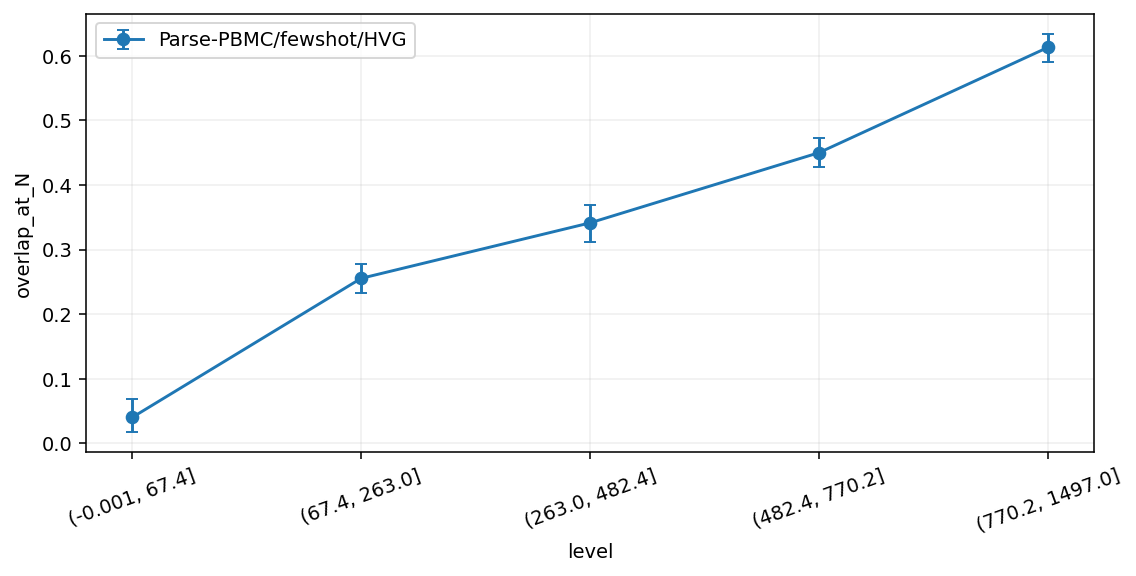

,panel,level,n,mean,lo,hi
0,Parse-PBMC/fewshot/SE,"(-0.001, 8.4]",50,0.053524,0.024663,0.087338
1,Parse-PBMC/fewshot/SE,"(8.4, 201.4]",49,0.200333,0.170501,0.231728
2,Parse-PBMC/fewshot/SE,"(201.4, 398.6]",50,0.376567,0.350312,0.401835
3,Parse-PBMC/fewshot/SE,"(398.6, 698.8]",49,0.515648,0.499957,0.531380
4,Parse-PBMC/fewshot/SE,"(698.8, 1497.0]",50,0.663632,0.643098,0.685810


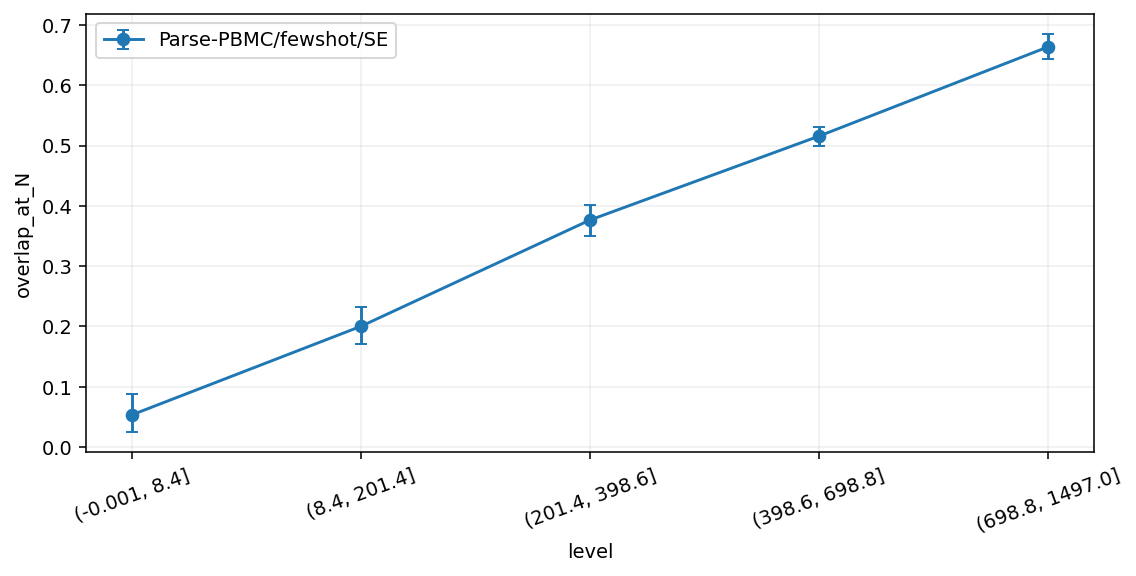

,panel,level,n,mean,lo,hi
0,Parse-PBMC/zeroshot/HVG,"(-0.001, 63.8]",90,0.014848,0.004167,0.028892
1,Parse-PBMC/zeroshot/HVG,"(63.8, 238.0]",92,0.102799,0.090031,0.116893
2,Parse-PBMC/zeroshot/HVG,"(238.0, 467.0]",88,0.199540,0.180809,0.218906
3,Parse-PBMC/zeroshot/HVG,"(467.0, 725.4]",90,0.362661,0.338240,0.388008
4,Parse-PBMC/zeroshot/HVG,"(725.4, 1494.0]",90,0.541279,0.517192,0.565613


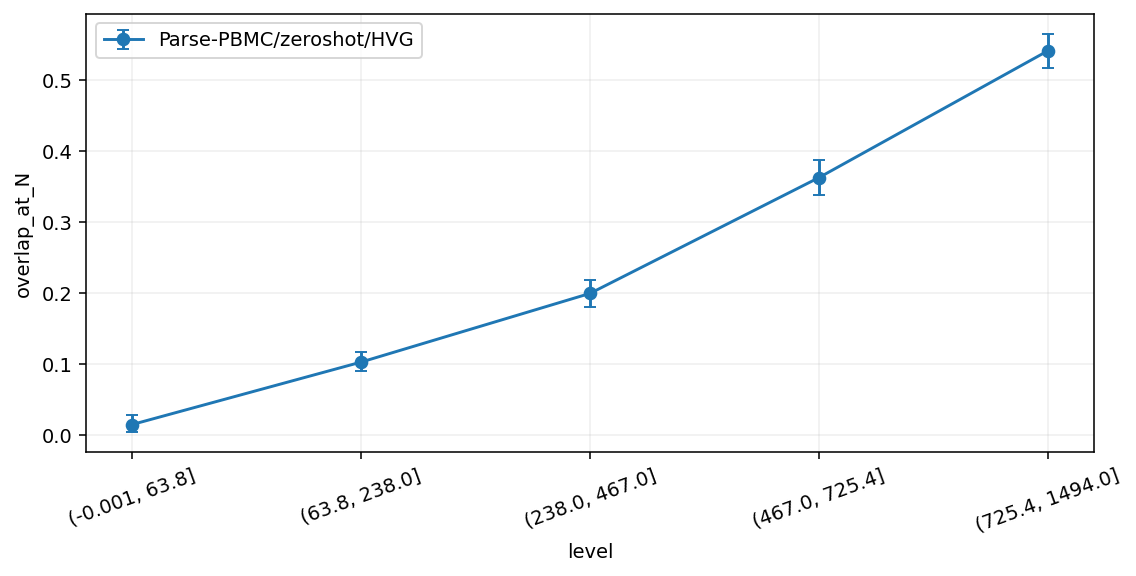

,panel,level,n,mean,lo,hi
0,Parse-PBMC/zeroshot/SE,"(-0.001, 63.8]",90,0.043669,0.024066,0.065362
1,Parse-PBMC/zeroshot/SE,"(63.8, 238.0]",92,0.113207,0.102657,0.124807
2,Parse-PBMC/zeroshot/SE,"(238.0, 467.0]",88,0.307743,0.288466,0.326701
3,Parse-PBMC/zeroshot/SE,"(467.0, 725.4]",90,0.464587,0.451945,0.476536
4,Parse-PBMC/zeroshot/SE,"(725.4, 1494.0]",90,0.640062,0.623727,0.656294


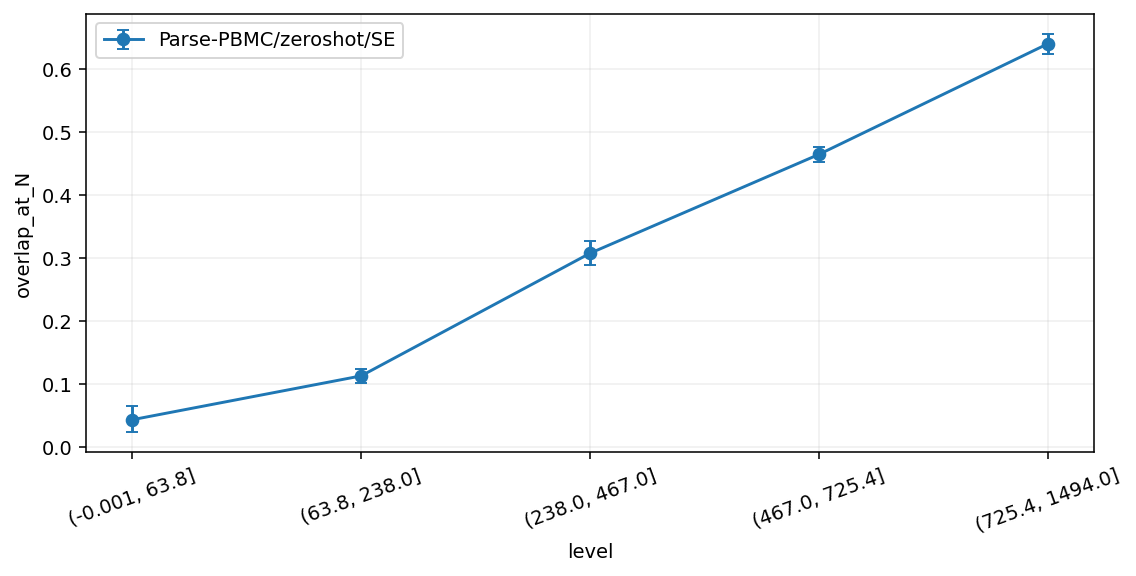

,panel,level,n,mean,lo,hi
0,Replogle-Nadig/fewshot/HVG,"(0.999, 25.0]",839,0.026393,0.021774,0.031221
1,Replogle-Nadig/fewshot/HVG,"(25.0, 67.0]",795,0.108670,0.100354,0.117835
2,Replogle-Nadig/fewshot/HVG,"(67.0, 165.0]",806,0.214168,0.202716,0.225336
3,Replogle-Nadig/fewshot/HVG,"(165.0, 382.0]",807,0.307136,0.294172,0.320348
4,Replogle-Nadig/fewshot/HVG,"(382.0, 1355.0]",811,0.495712,0.481718,0.509310


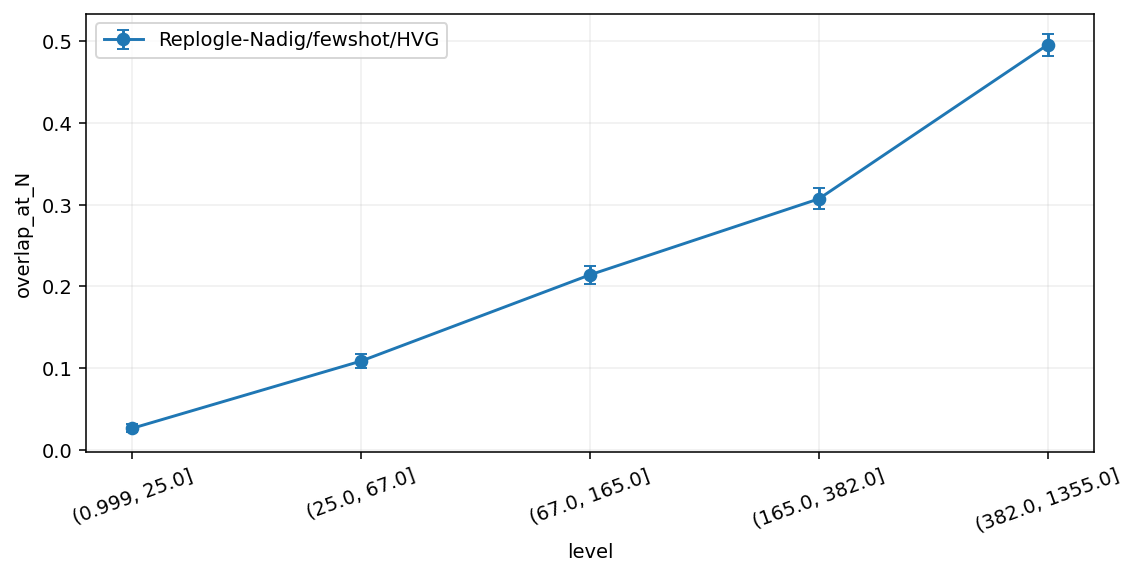

,panel,level,n,mean,lo,hi
0,Replogle-Nadig/fewshot/SE,"(0.999, 25.0]",839,0.009375,0.007102,0.011854
1,Replogle-Nadig/fewshot/SE,"(25.0, 67.0]",795,0.041436,0.037259,0.046240
2,Replogle-Nadig/fewshot/SE,"(67.0, 165.0]",806,0.106275,0.099089,0.113181
3,Replogle-Nadig/fewshot/SE,"(165.0, 382.0]",807,0.233029,0.221860,0.244299
4,Replogle-Nadig/fewshot/SE,"(382.0, 1355.0]",811,0.499919,0.486556,0.513840


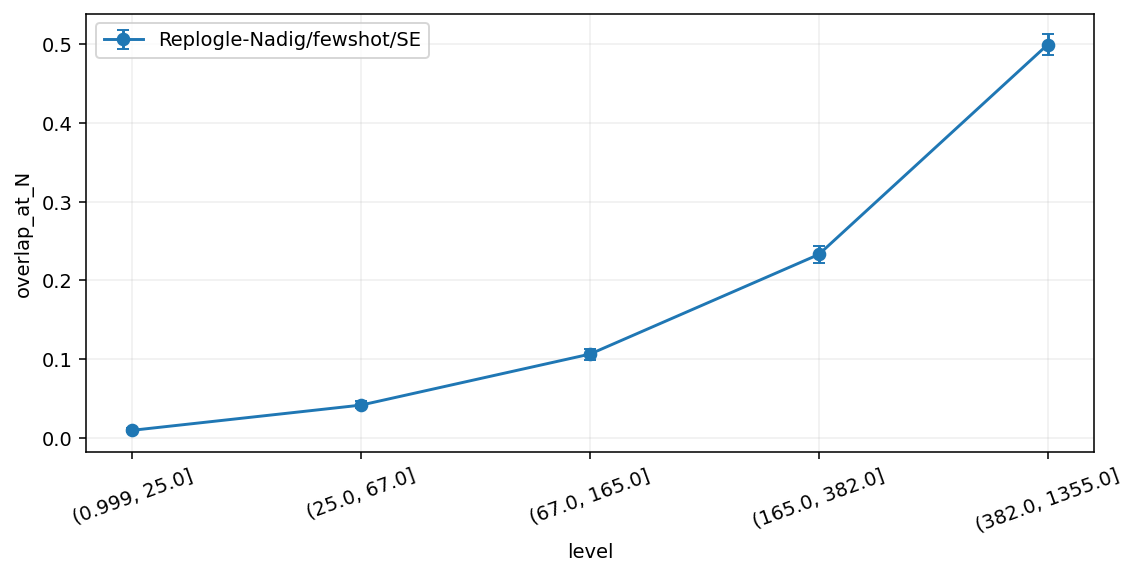

,panel,level,n,mean,lo,hi
0,Replogle-Nadig/zeroshot/HVG,"(0.999, 24.0]",1175,0.019347,0.016012,0.022729
1,Replogle-Nadig/zeroshot/HVG,"(24.0, 66.0]",1137,0.070026,0.064646,0.075499
2,Replogle-Nadig/zeroshot/HVG,"(66.0, 160.0]",1144,0.131919,0.125366,0.138286
3,Replogle-Nadig/zeroshot/HVG,"(160.0, 386.0]",1153,0.186203,0.178181,0.194330
4,Replogle-Nadig/zeroshot/HVG,"(386.0, 1402.0]",1150,0.279974,0.270361,0.290021


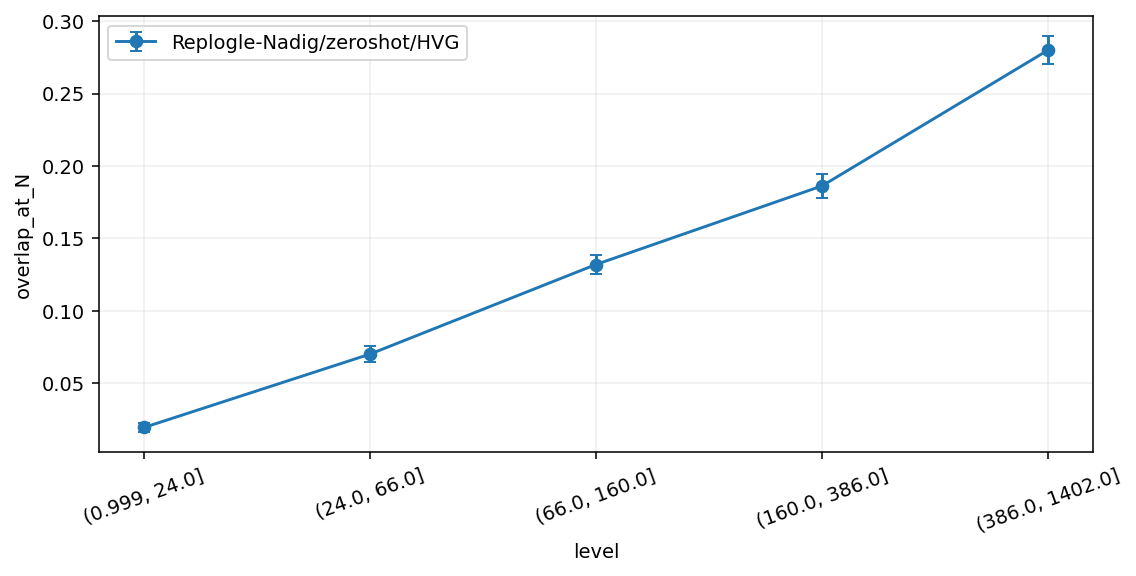

,panel,level,n,mean,lo,hi
0,Replogle-Nadig/zeroshot/SE,"(0.999, 24.0]",1175,0.008308,0.006500,0.010199
1,Replogle-Nadig/zeroshot/SE,"(24.0, 66.0]",1137,0.022394,0.019951,0.025070
2,Replogle-Nadig/zeroshot/SE,"(66.0, 160.0]",1144,0.048614,0.045500,0.051901
3,Replogle-Nadig/zeroshot/SE,"(160.0, 386.0]",1153,0.096258,0.090301,0.102131
4,Replogle-Nadig/zeroshot/SE,"(386.0, 1402.0]",1150,0.193775,0.183406,0.204280


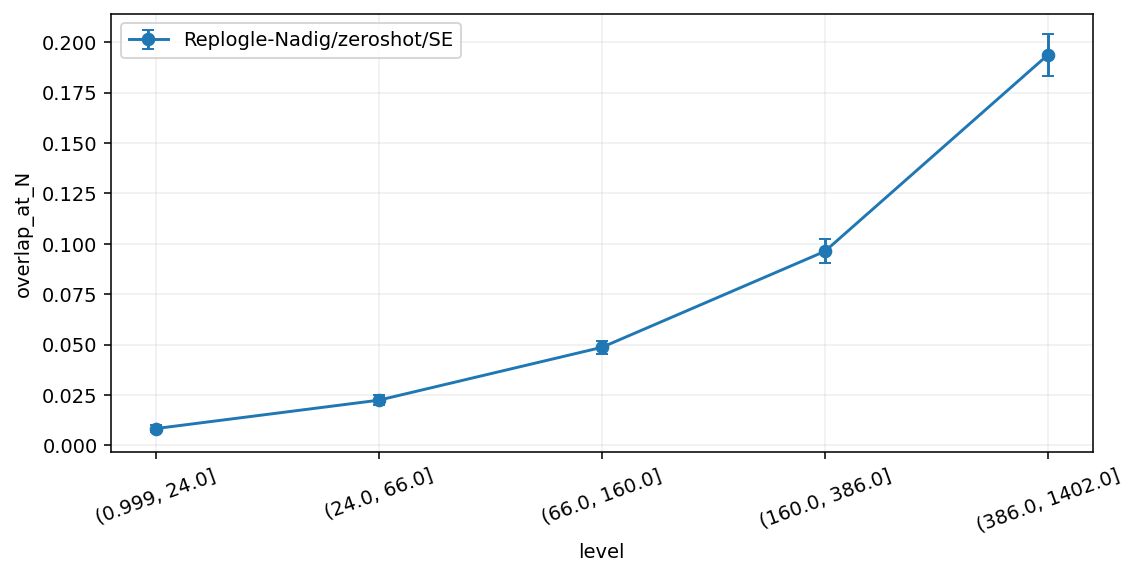

,panel,level,n,mean,lo,hi
0,Tahoe-100M/fewshot/HVG,"(12.999, 285.0]",742,0.432285,0.425617,0.439021
1,Tahoe-100M/fewshot/HVG,"(285.0, 372.0]",732,0.475026,0.469042,0.481255
2,Tahoe-100M/fewshot/HVG,"(372.0, 460.0]",733,0.521256,0.515264,0.527038
3,Tahoe-100M/fewshot/HVG,"(460.0, 590.0]",733,0.559585,0.554366,0.564809
4,Tahoe-100M/fewshot/HVG,"(590.0, 1617.0]",734,0.639604,0.633727,0.645518


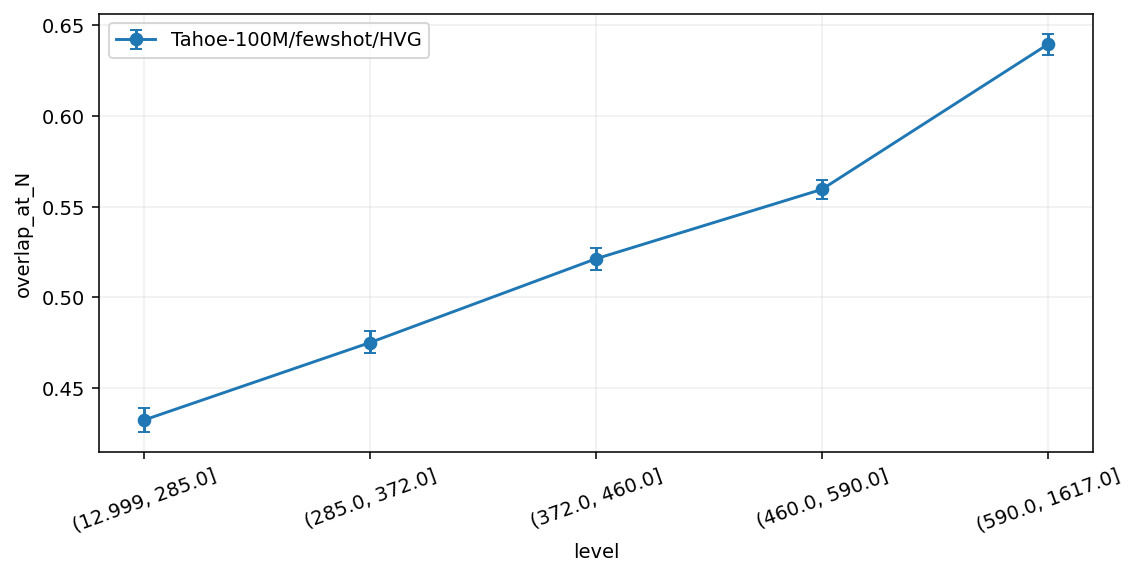

,panel,level,n,mean,lo,hi
0,Tahoe-100M/fewshot/SE,"(12.999, 285.0]",742,0.449805,0.442720,0.456811
1,Tahoe-100M/fewshot/SE,"(285.0, 372.0]",732,0.483076,0.476770,0.489847
2,Tahoe-100M/fewshot/SE,"(372.0, 460.0]",733,0.506480,0.498464,0.514081
3,Tahoe-100M/fewshot/SE,"(460.0, 590.0]",733,0.539497,0.532344,0.546300
4,Tahoe-100M/fewshot/SE,"(590.0, 1617.0]",734,0.600002,0.592919,0.606721


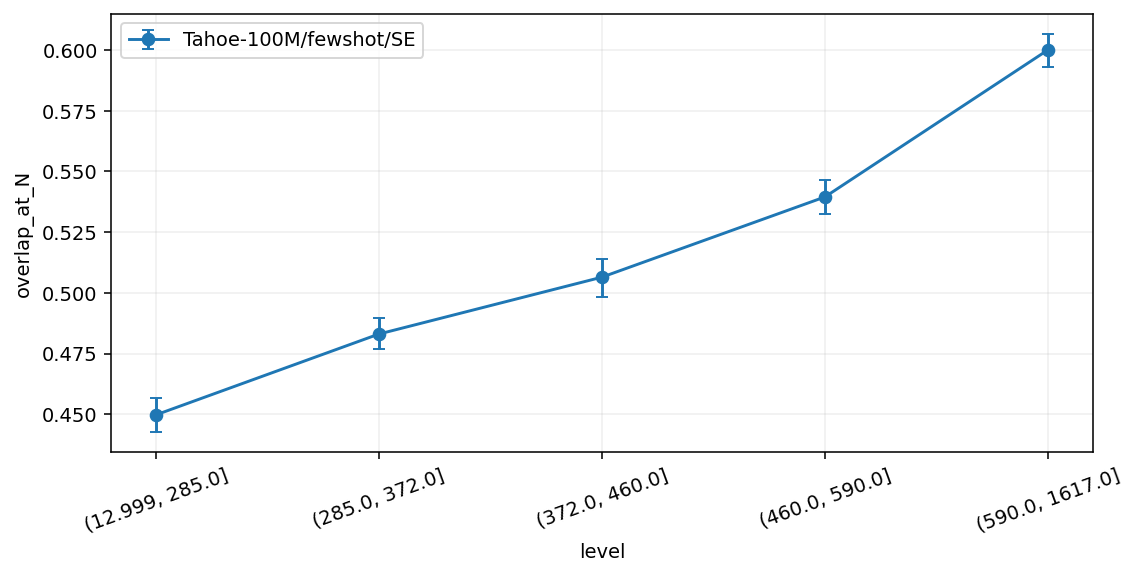

,panel,level,n,mean,lo,hi
0,Tahoe-100M/zeroshot/HVG,"(12.999, 288.0]",1145,0.150428,0.144857,0.156265
1,Tahoe-100M/zeroshot/HVG,"(288.0, 375.0]",1142,0.190390,0.182839,0.197491
2,Tahoe-100M/zeroshot/HVG,"(375.0, 461.0]",1125,0.230861,0.223027,0.238584
3,Tahoe-100M/zeroshot/HVG,"(461.0, 589.4]",1135,0.272872,0.265755,0.279625
4,Tahoe-100M/zeroshot/HVG,"(589.4, 1617.0]",1137,0.365293,0.358405,0.372053


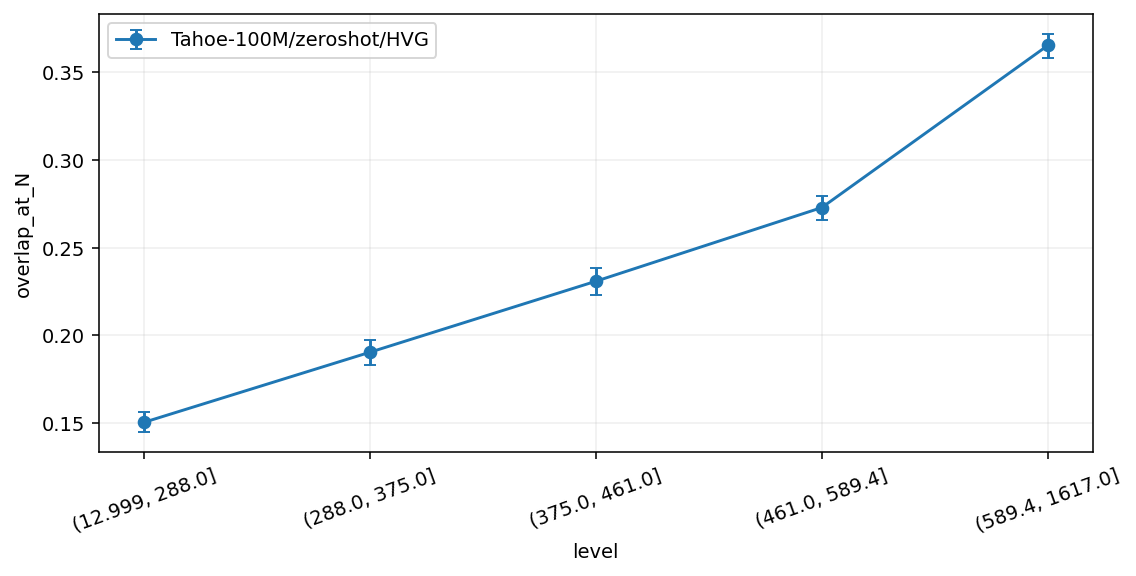

,panel,level,n,mean,lo,hi
0,Tahoe-100M/zeroshot/SE,"(12.999, 288.0]",1145,0.040914,0.039533,0.042325
1,Tahoe-100M/zeroshot/SE,"(288.0, 375.0]",1142,0.059643,0.057852,0.061382
2,Tahoe-100M/zeroshot/SE,"(375.0, 461.0]",1125,0.098404,0.095919,0.100927
3,Tahoe-100M/zeroshot/SE,"(461.0, 589.4]",1135,0.164054,0.160707,0.167256
4,Tahoe-100M/zeroshot/SE,"(589.4, 1617.0]",1137,0.348828,0.341706,0.356205


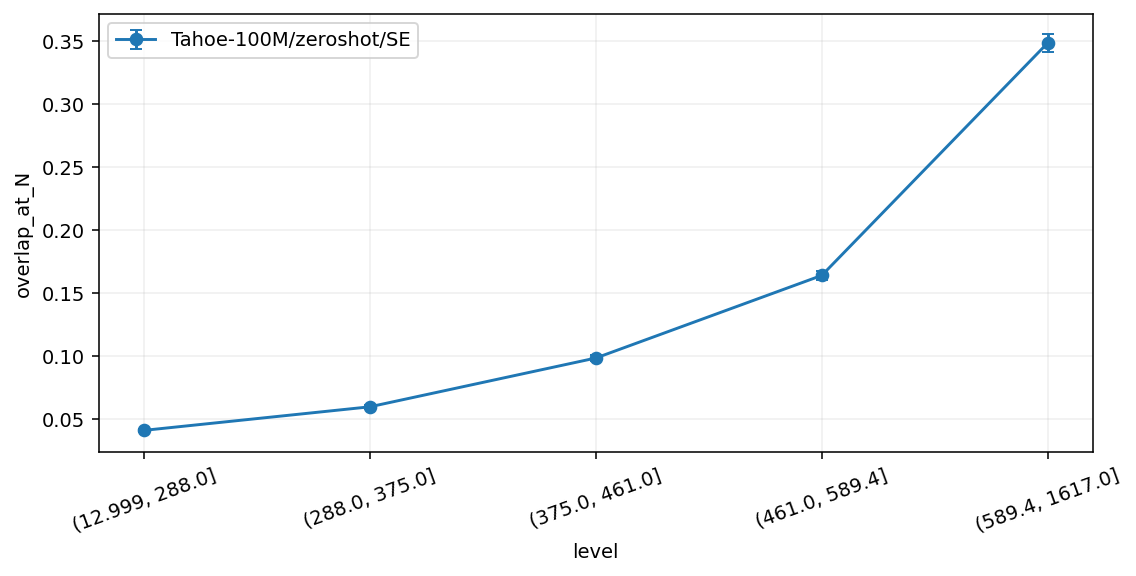

,family,protocol,representation,rho,p
0,Parse-PBMC,fewshot,HVG,0.890796,1.582604e-107
1,Parse-PBMC,fewshot,SE,0.942633,3.305984e-119
2,Parse-PBMC,zeroshot,HVG,0.926164,7.466349e-192
3,Parse-PBMC,zeroshot,SE,0.951797,4.616310e-232
4,Replogle-Nadig,fewshot,HVG,0.750857,0.000000e+00
5,Replogle-Nadig,fewshot,SE,0.824438,0.000000e+00
6,Replogle-Nadig,zeroshot,HVG,0.674063,0.000000e+00
7,Replogle-Nadig,zeroshot,SE,0.634725,0.000000e+00
8,Tahoe-100M,fewshot,HVG,0.679581,0.000000e+00
9,Tahoe-100M,fewshot,SE,0.484341,1.851930e-215


In [7]:
rows=[]
for keys,z in axis_panels:
    rho,p=spearmanr(z.de_nsig_counts_real,z.overlap_at_N);rows.append({'family':keys[0],'protocol':keys[1],'representation':keys[2],'rho':rho,'p':p})
    draw(z,'level','overlap_at_N','panel')
results=pd.DataFrame(rows);display(results)


## 6. What the agent decided, and why

In [8]:
print('Decision: retain observed perturbation strength as an intrinsic-difficulty control, not a prospective novelty feature.')
print('Positive associations:',int((results.rho>0).sum()),'of',len(results))

Decision: retain observed perturbation strength as an intrinsic-difficulty control, not a prospective novelty feature.
Positive associations: 12 of 12


In [9]:
(WORK/'execution_record.json').write_text(json.dumps({'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'official_sources':SOURCES,'input_rows':len(raw),'model_inference_performed':False,'external_custom_code_used':False},indent=2))

32015